# Chapter 08 제출 답안 — 작은 데이터 분석 프로젝트 완성하기

- 이름: 송누리 / GitHub ID: HauserNR
- 작성일·미래 날짜 검증 기준일: 2026-11-04
- 최종 Notebook URL: [chapter08/chapter08.ipynb](https://github.com/HauserNR/llm-data-analysis-study/blob/main/chapter08/chapter08.ipynb)

공식 Notebook 38개 셀을 복사하여 순서를 유지하고, 경로·공개 산출물 저장·그래프 검증·재실행 부분을 보완했다. 공식 셀은 `official_cell_index`로 추적하며 내려받은 원본은 `references/`에 보관한다. 답안은 관련 실행 결과 아래에 작성했다.

공식 자료: [실습 가이드](https://github.com/GilbertMoon/llm-data-analysis-course/blob/main/practice/chapter08/chapter08.md), [Notebook](https://github.com/GilbertMoon/llm-data-analysis-course/blob/main/notebooks/ch08_midterm_project.ipynb), [답안 템플릿](https://github.com/GilbertMoon/llm-data-analysis-course/blob/main/practice/chapter08/templates/chapter08_assignment.md).

## 답안 1. 실행 전 분석 질문·계산 범위

| 질문 | 분석 대상·범위 | 데이터 | 지표 | 검증 가능한 완료 기준 |
|---|---|---|---|---|
| Q1. 카테고리별 완료 주문 금액은 어떻게 다른가? | completed 주문의 모든 상세, 날짜 제외 없음 | items·orders·products | 수량, 금액, 비중 | 카테고리 합계 = completed source, 비중 합계 약 100% |
| Q2. 월별 완료 주문 금액과 주문 수는 어떻게 변하는가? | 위와 같은 completed 상세를 주문일 월별 집계 | items·orders | 금액, 고유 주문 수, 주문당 금액 | 월 합계 = source, 월 주문 수 합 = completed 고유 주문 수, 날짜 오류 0 |
| Q3. 완료 금액 상위 고객의 구매 규모·횟수는 어떠한가? | 위와 같은 completed 상세의 구매 고객 | items·orders·customers | 고객 금액, 고유 주문 수, 주문당 금액 | 모든 고객 합계 = source, 고객 연결 미매칭 0, 공개 ID·이름 없음 |

금액은 `quantity × unit_price`의 합이며 `order_status == "completed"`를 세 질문에 동일하게 적용한다. 주문 수는 `order_id.nunique()`이다. 주문 상태 분포만 전체 주문 헤더를 사용한다. 금액 단위는 실습 데이터의 원으로 표기하며 할인·배송비·세금·원가 정보가 없어 회계상 순매출·이익으로 해석하지 않는다.

이번 장은 공식 지시대로 **루트 `data/raw` 4개 파일에서 새로 시작**한다. Chapter 06·07은 Chapter 05에서 만든 별도 processed 입력을 사용했으므로 장 사이 결과를 동일 모집단의 변화로 비교하지 않는다. 원본과 기존 processed 파일은 덮어쓰지 않고 해시로 보존 여부를 확인한다. 개인정보가 포함된 행 단위 전처리 결과는 메모리에서만 사용한다.

커널을 재시작한 뒤 전체 실행한다. 저장소 루트·chapter08 폴더에서 실행 가능하며 네트워크나 API 키는 필요 없다. 공식 8개 Validation과 추가 검증, 실제 그래프 값 검증을 모두 통과해야 완료로 판단한다.

# 8장. 작은 데이터 분석 프로젝트 완성하기

이 노트북은 **질문 → 원본 데이터 점검 → 전처리 → PK/FK 검증 → 안전한 병합 → completed 범위 집계 → 총합 대조 → 시각화 → 보고서 → 최종 Validation**을 하나의 재현 가능한 프로젝트로 연결합니다.

> 코드가 끝까지 실행되었다는 사실만으로 프로젝트가 검증된 것은 아닙니다. 같은 의미의 숫자와 공개 산출물이 정해 둔 기준을 함께 통과해야 합니다.


## 학습 목표

- 원본 데이터를 보존하며 전처리합니다.
- 주요 PK의 결측·중복과 FK 미매칭을 확인합니다.
- `validate`와 `indicator` 관점으로 병합 결과를 검증합니다.
- `line_total = quantity × unit_price`를 다시 확인합니다.
- 금액성 분석은 `order_status == "completed"` 범위를 사용합니다.
- 카테고리·월·고객 금액 합계를 같은 source total과 대조합니다.
- 날짜 오류로 월별 금액이 누락되지 않는지 확인합니다.
- 공개 고객 결과에서 원본 고객 ID와 직접 식별정보를 제거합니다.
- 결과 CSV, 그래프, Markdown 보고서와 PASS/FAIL Evidence를 저장합니다.
- 전체 파이프라인을 다시 실행해 재현성을 확인합니다.


## 1. 프로젝트 루트와 출력 폴더 설정

VS Code에서 현재 작업 폴더가 프로젝트 루트 또는 `notebooks`일 수 있으므로 상위 폴더를 탐색합니다.


In [1]:
from pathlib import Path
import sys, os, platform, hashlib
os.environ.setdefault("MPLCONFIGDIR", "/tmp/ch08-matplotlib")
import numpy as np
import pandas as pd
import matplotlib
from IPython.display import display, Image

def find_project_root(start_path):
    for candidate in [Path(start_path).resolve(), *Path(start_path).resolve().parents]:
        if (candidate / "chapter08" / "src" / "midterm_project.py").exists() and (candidate / "data/raw/orders.csv").exists():
            return candidate
    raise FileNotFoundError("저장소 루트를 찾을 수 없습니다.")

PROJECT_ROOT = find_project_root(Path.cwd())
CHAPTER_DIR = PROJECT_ROOT / "chapter08"
RAW_DIR = PROJECT_ROOT / "data/raw"
PROCESSED_DIR = CHAPTER_DIR / "data/processed"  # 호환 인자: 행 단위 파일은 저장하지 않음
REPORT_DIR = CHAPTER_DIR / "reports"
FIGURE_DIR = CHAPTER_DIR / "images"
for path in [REPORT_DIR, FIGURE_DIR]:
    path.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(CHAPTER_DIR))
from src.evidence import input_manifest, extra_evidence
manifest_before = input_manifest(PROJECT_ROOT)
print("Python", platform.python_version(), "pandas", pd.__version__, "numpy", np.__version__, "matplotlib", matplotlib.__version__)
print("Python 실행 파일:", sys.executable)
print("입력: data/raw / 출력: chapter08/reports, chapter08/images")


Python 3.12.0 pandas 3.0.5 numpy 2.5.3 matplotlib 3.11.1
Python 실행 파일: /Users/kjj/MyLLMGit/llm-data-analysis-study/.venv/bin/python
입력: data/raw / 출력: chapter08/reports, chapter08/images


## 2. 프로젝트 함수 불러오기

Notebook과 일괄 실행 스크립트가 같은 `src.midterm_project` 함수를 사용하도록 하여 계산 기준이 어긋나는 문제를 줄입니다.


In [2]:
from src.data_loader import load_sales_data
from src.preprocessing import (
    compare_shapes,
    preprocess_sales_data,
    save_processed_data,
    validate_relationships,
)
from src.midterm_project import (
    FORBIDDEN_CUSTOMER_COLUMNS,
    build_analysis_tables,
    build_interpretation_notes,
    build_key_duplicate_checks,
    build_midterm_report,
    build_project_validation,
    create_project_figures,
    run_midterm_project,
    save_project_tables,
    summarize_datasets,
)


## 3. 원본 데이터 확인

프로젝트는 `data/raw`의 원본 4개 파일에서 시작합니다. 파일이 없다면 프로젝트 루트에서 `python scripts/generate_sample_data.py`를 먼저 실행합니다.


In [3]:
raw_data = load_sales_data(RAW_DIR)

dataset_summary = summarize_datasets(raw_data)
display(dataset_summary)

for name, df in raw_data.items():
    print(f"\n===== {name} =====")
    print("shape:", df.shape)
    print("columns:", df.columns.tolist())
    print("missing values:", int(df.isna().sum().sum()))
    print("duplicated rows:", int(df.duplicated().sum()))


,dataset,rows,columns,missing_values,duplicated_rows
0,customers,150,6,0,0
1,products,100,4,0,0
2,orders,300,5,0,0
3,order_items,764,5,0,0



===== customers =====
shape: (150, 6)
columns: ['customer_id', 'name', 'gender', 'age', 'city', 'signup_date']
missing values: 0
duplicated rows: 0

===== products =====
shape: (100, 4)
columns: ['product_id', 'product_name', 'category', 'price']
missing values: 0
duplicated rows: 0

===== orders =====
shape: (300, 5)
columns: ['order_id', 'customer_id', 'order_date', 'payment_method', 'order_status']
missing values: 0
duplicated rows: 0

===== order_items =====
shape: (764, 5)
columns: ['order_item_id', 'order_id', 'product_id', 'quantity', 'unit_price']
missing values: 0
duplicated rows: 0


## 4. 원본을 보존하며 전처리

`preprocess_sales_data()`는 원본 DataFrame을 직접 수정하지 않고 전처리된 복사본을 반환합니다. 전처리 전후 행 수가 달라졌다면 그 이유를 설명할 수 있어야 합니다.


In [4]:
processed_data = preprocess_sales_data(raw_data)
preprocessing_comparison = compare_shapes(raw_data, processed_data)
display(preprocessing_comparison)
column_checks = []
for stage, data in [("raw", raw_data), ("processed", processed_data)]:
    for name, df in data.items():
        for col in df:
            column_checks.append({"stage": stage, "dataset": name, "column": col, "dtype": str(df[col].dtype), "missing_count": int(df[col].isna().sum())})
column_checks = pd.DataFrame(column_checks)
display(column_checks)
print("행 단위 processed CSV는 저장하지 않음: 공개 산출물의 개인정보 최소화")


,dataset,rows_raw,columns_raw,rows_processed,columns_processed
0,customers,150,6,150,6
1,order_items,764,5,764,6
2,orders,300,5,300,7
3,products,100,4,100,4


,stage,dataset,column,dtype,missing_count
0,raw,customers,customer_id,int64,0
1,raw,customers,name,str,0
2,raw,customers,gender,str,0
3,raw,customers,age,int64,0
4,raw,customers,city,str,0
5,raw,customers,signup_date,str,0
6,raw,products,product_id,int64,0
7,raw,products,product_name,str,0
8,raw,products,category,str,0
9,raw,products,price,int64,0


행 단위 processed CSV는 저장하지 않음: 공개 산출물의 개인정보 최소화


## 답안 2. 입력·전처리 검증 판단

원본 shape는 customers **150×6**, products **100×4**, orders **300×5**, order_items **764×5**이다. 각 컬럼의 dtype·결측은 위 표와 `reports/ch08_column_checks.csv`로 확인했다. 원본·전처리 후 모든 컬럼 결측 0건, 전체 행 중복 0건이다. PK는 다음 단계에서 별도 검증한다.

공식 전처리 규칙은 문자열 공백 제거, 나이 숫자 변환·결측 중앙값 대체, 도시 결측 Unknown, 상태 표준화, 날짜 변환, 가격·수량·단가 숫자 변환, 0 이하 값 제외, 완전 중복 제거이다. 이번 원본에서는 네 테이블 모두 **제외 0행**으로 150·100·300·764행이 유지됐다. 주문에 `order_month`, `order_dayofweek` 2열, 상세에 `line_total` 1열만 추가되어 열 수는 6·4·7·6이다. 나이·도시 결측 대체와 불량 수치·중복 제거의 대상도 0건이다.

판단: 이번 데이터에서는 행 제거 때문에 완료 금액이나 FK 연결이 달라지지 않는다. 이전 장의 결함이 있는 processed 데이터를 무조건 신뢰하거나 재사용하지 않았다. 한계: 자료의 구조적 정상 여부와 실거래의 정확성은 다르며 원천 시스템 대조는 수행하지 않았다.

## 5. PK와 FK를 먼저 검증

전체 행 중복과 PK 중복은 다릅니다. 고객·상품·주문·주문 상세의 PK는 **결측 0, 중복 0**이어야 합니다. FK는 부모 테이블에 없는 참조 ID가 0건이어야 합니다.


In [5]:
key_duplicate_checks = build_key_duplicate_checks(processed_data)
relationship_checks = validate_relationships(processed_data).copy()

if not relationship_checks.empty:
    relationship_checks["status"] = (
        relationship_checks["invalid_count"]
        .eq(0)
        .map({True: "PASS", False: "FAIL"})
    )

display(key_duplicate_checks)
display(relationship_checks)

assert key_duplicate_checks["status"].eq("PASS").all(), "PK Validation 실패"
assert (
    not relationship_checks.empty
    and relationship_checks["invalid_count"].eq(0).all()
), "FK Validation 실패"

print("PK/FK Gate: PASS")


,dataset,key,missing_count,duplicate_count,status,detail
0,customers,customer_id,0,0,PASS,
1,products,product_id,0,0,PASS,
2,orders,order_id,0,0,PASS,
3,order_items,order_item_id,0,0,PASS,


,check,invalid_count,status
0,orders.customer_id exists in customers.custome...,0,PASS
1,order_items.order_id exists in orders.order_id,0,PASS
2,order_items.product_id exists in products.prod...,0,PASS


PK/FK Gate: PASS


## 답안 3. PK/FK·병합 기준

customers.customer_id, products.product_id, orders.order_id, order_items.order_item_id는 각각 결측 **0**, 중복 **0**으로 PASS다. 세 FK 관계의 미매칭도 모두 **0건**이다. 원본 PK/FK도 추가 검증에서 같은 기준으로 다시 확인한다. 키 값 자체는 출력하지 않는다.

판단: 참조 무결성을 확인한 후 병합을 진행할 수 있다. `merge()`가 오류 없이 끝났다는 사실과 실제 행·금액 보존 여부는 다음 표에서 별도로 확인한다.

## 6. 안전한 병합과 계산 관계 검증

`build_analysis_tables()`는 다음을 한 번에 준비합니다.

- 주문 상세 → 주문: `many_to_one`
- 주문 상세 → 상품: `many_to_one`
- 고객 집계 → 고객: `one_to_one`
- 병합 전후 행 수와 미매칭 확인
- `line_total = quantity × unit_price` 확인
- completed 주문 범위 확정
- 날짜 오류 확인


In [6]:
analysis_tables = build_analysis_tables(processed_data)

display(analysis_tables["merge_checks"])
display(analysis_tables["line_total_check"])
display(analysis_tables["date_checks"])
display(analysis_tables["amount_scope_summary"])

assert analysis_tables["merge_checks"]["status"].eq("PASS").all()
assert analysis_tables["line_total_check"]["status"].eq("PASS").all()

print("병합 / line_total Gate: PASS")


,merge,validate,before_rows,after_rows,row_count_preserved,unmatched_count,status
0,order_id → orders,many_to_one,764,764,True,0,PASS
1,product_id → products,many_to_one,474,474,True,0,PASS
2,customer_id → customers,one_to_one,100,100,True,0,PASS


,check,source,row_count,mismatch_count,status
0,line_total = quantity × unit_price,existing,764,0,PASS


,check,invalid_count,affected_amount,status
0,completed rows with invalid order_date,0,0.0,PASS


,scope,amount,detail_rows
0,all_order_items,255610000.0,764
1,completed_order_items,148990000.0,474
2,excluded_non_completed,106620000.0,290


병합 / line_total Gate: PASS


주문 병합은 `many_to_one`, **764→764행**, 미매칭 0건이다. 상품 병합은 completed 상세만 대상으로 `many_to_one`, **474→474행**, 미매칭 0건이다. 고객 집계 후 병합은 `one_to_one`이며 실제 전후 행 수는 위 표와 같다. 모든 병합은 `indicator=True`로 `left_only`를 확인했다.

`line_total`은 764행 모두 `quantity × unit_price`와 일치한다. 원본에는 line_total이 없어 생성 후 재검증했으며, 원본 ID 집합으로 merge 없이 계산한 금액도 마지막 추가 검증에서 비교한다.

전체 상세 **764행 / 300주문 / 255,610,000원**, completed 상세 **474행 / 184주문 / 148,990,000원**이다. 비완료 상세 **290행 / 106,620,000원**은 세 금액성 분석에서 제외한다. 이 차이를 전처리 손실이나 누락 매출로 해석하지 않는다.

## 7. 핵심 분석 결과 확인

세 금액성 결과는 같은 `completed_order_sales`에서 출발합니다. 주문 상태 분포만 전체 주문을 사용합니다.


In [7]:
category_sales = analysis_tables["category_sales"]
monthly_sales = analysis_tables["monthly_sales"]
customer_sales_internal = analysis_tables["customer_sales"]
customer_sales_public = analysis_tables["customer_sales_public"]
order_status_summary = analysis_tables["order_status_summary"]

display(category_sales)
display(monthly_sales)
display(customer_sales_public.head(10))
display(order_status_summary)

print("내부 고객 결과 컬럼:", customer_sales_internal.columns.tolist())
print("공개 고객 결과 컬럼:", customer_sales_public.columns.tolist())


,category,total_quantity,total_sales,sales_ratio
0,스포츠,295,31743000,21.31
1,전자기기,259,26400000,17.72
2,생활용품,272,23915000,16.05
3,뷰티,223,23383000,15.69
4,식품,133,16573000,11.12
5,도서,149,16389000,11.00
6,패션,111,10587000,7.11


,order_month,total_sales,order_count,avg_order_value
0,2025-09,3529000,5,705800.0
1,2025-10,16197000,16,1012312.0
2,2025-11,11694000,17,687882.0
3,2025-12,12319000,14,879929.0
4,2026-01,5144000,8,643000.0
5,2026-02,10034000,12,836167.0
6,2026-03,14254000,18,791889.0
7,2026-04,16634000,20,831700.0
8,2026-05,14367000,19,756158.0
9,2026-06,8943000,9,993667.0


,customer_label,city,order_count,total_sales,avg_order_value
0,Customer 01,성남,5,4100000,820000.0
1,Customer 02,고양,4,3996000,999000.0
2,Customer 03,수원,4,3880000,970000.0
3,Customer 04,서울,5,3590000,718000.0
4,Customer 05,서울,4,3523000,880750.0
5,Customer 06,인천,2,3191000,1595500.0
6,Customer 07,성남,2,3178000,1589000.0
7,Customer 08,광주,3,3153000,1051000.0
8,Customer 09,서울,4,3093000,773250.0
9,Customer 10,부산,2,2990000,1495000.0


,order_status,order_count,order_ratio
0,completed,184,61.33
1,cancelled,64,21.33
2,refunded,52,17.33


내부 고객 결과 컬럼: ['customer_id', 'customer_label', 'city', 'order_count', 'total_sales', 'avg_order_value']
공개 고객 결과 컬럼: ['customer_label', 'city', 'order_count', 'total_sales', 'avg_order_value']


## 8. 같은 의미의 금액 총합을 교차 검증

같은 completed 범위에서 만든 결과라면 다음 네 금액이 일치해야 합니다.

```text
completed source total
= category total
= monthly total
= customer total
```

날짜 오류가 있으면 월별 합계가 source total보다 작아질 수 있으므로 별도 Gate로 확인합니다.


In [8]:
total_consistency = analysis_tables["total_consistency_check"]
display(total_consistency)

assert total_consistency["matches_completed"].all(), "Total consistency Gate 실패"
assert analysis_tables["date_checks"]["status"].eq("PASS").all(), "날짜 Gate 실패"

print("Total consistency / Date Gate: PASS")


,source,amount,difference_from_completed,matches_completed,status
0,completed_source,148990000.0,0.0,True,PASS
1,category,148990000.0,0.0,True,PASS
2,monthly,148990000.0,0.0,True,PASS
3,customer,148990000.0,0.0,True,PASS


Total consistency / Date Gate: PASS


## 답안 4. 핵심 EDA 결과 3개와 판단

**결과 1 — 카테고리(Q1)**

- 관찰: 스포츠 **31,743,000원(21.31%)**, 전자기기 **26,400,000원(17.72%)** 순이다. 스포츠 수량은 **295개**, 전자기기는 **259개**이다. 7개 카테고리 합계는 **148,990,000원**, 비중 합계는 **100.00%**이다.
- 나의 해석과 판단: 스포츠가 관찰된 완료 주문 금액의 가장 큰 부분을 차지한다. 스포츠가 전체의 과반을 차지하는 것은 아니다.
- 업무·분석적 의미: 카테고리별 단가·수량을 분리해 기여 차이를 검토할 우선 후보로 사용할 수 있다.
- 한계·추가 확인: 원가와 노출·방문 수가 없어 수익성·선호도·광고 효과를 단정할 수 없다.

**결과 2 — 월별(Q2)**

- 관찰: **2026-04 금액 16,634,000원 / 20주문 / 주문당 831,700원**으로 월 금액이 가장 높다. **2026-07도 20주문**이지만 금액은 **14,639,000원 / 주문당 731,950원**이다. 13개월 합계는 148,990,000원·184주문이다.
- 나의 해석과 판단: 주문 수가 같아도 주문당 금액 차이로 월 금액이 다르다. 이 비교는 수치 분해이며 가격 변경 등 원인을 입증하지 않는다.
- 업무·분석적 의미: 월 금액 증감을 주문 수와 주문당 금액으로 나누고 상품 구성까지 확인할 가치가 있다.
- 한계·추가 확인: 관측 주문일은 **2025-09-15~2026-09-15**이며 양 끝 9월은 월 전체를 포함하지 않는다. 달력 일수로 보정하지 않은 월 금액의 단순 증감을 성장률·계절성으로 해석하지 않는다. 관측 구간 내 누락 월은 0개이며 월별 누락·미수집 여부는 원천 자료 확인이 필요하다.

**결과 3 — 익명 고객(Q3)**

- 관찰: 완료 구매 고객은 **100명**이다. Customer 01은 **4,100,000원 / 5주문 / 주문당 820,000원**이다. 상위 10명 합계 **34,694,000원(23.29%)**, 완료 주문 수 합 **35건**이다.
- 나의 해석과 판단: 최고 금액 고객의 구매는 5건으로 분산되어 있다. 상위 고객 모두를 일회성 고액 구매자로 묶지 않는다.
- 업무·분석적 의미: 구매 빈도와 주문당 금액을 분리한 후 최근 구매일·기간을 보완해 고객군 분석을 확장할 수 있다.
- 한계·추가 확인: 고객 가입 시점별 관측 기간 차이를 보정하지 않았다. 금액 순위를 장기 충성도·고객 가치·이익 순위로 단정하지 않는다. 순위 라벨은 이 분석 내 표시용이며 다른 실행·자료와의 고객 추적 식별자로 사용하지 않는다.

상태 분포(보조 점검): 전체 300주문 중 completed **184(61.33%)**, cancelled **64(21.33%)**, refunded **52(17.33%)**이다. 반올림으로 비중 합계가 99.99%일 수 있으며, 취소·환불 원인은 현재 컬럼으로 알 수 없다.

## 답안 5. Total consistency·날짜 검증

`completed source = category = monthly = customer = 148,990,000원`이며 차이는 모두 **0원**이다. 공식 비교는 `rtol=1e-9, atol=1e-6`, 추가 검증은 원 단위 정수 합계의 **정확 일치**를 사용한다. 모든 주문 날짜가 유효하며 completed 날짜 오류 **0행**, 영향 금액 **0원**이다. 날짜 제외 없이 같은 completed 모집단을 세 분석에 유지했다. 현재 입력에서는 총합 불일치나 수정한 FAIL이 없다.

## 9. 공개 고객 결과의 개인정보를 확인

내부 계산에는 `customer_id`가 필요할 수 있지만 공개 CSV·그래프·보고서에는 원본 고객 ID와 직접 식별정보를 포함하지 않습니다. 공개 라벨은 `Customer 01` 같은 순위 기반 라벨을 사용합니다.


In [9]:
forbidden = sorted(
    FORBIDDEN_CUSTOMER_COLUMNS.intersection(customer_sales_public.columns)
)
print("공개 결과 금지 컬럼:", forbidden)

assert not forbidden, "Privacy Gate 실패"
assert "customer_id" not in customer_sales_public.columns
print("Privacy Gate: PASS")


공개 결과 금지 컬럼: []
Privacy Gate: PASS


## 10. 최종 PASS/FAIL Validation

지금까지의 핵심 Gate를 하나의 표로 정리합니다. 하나라도 FAIL이면 결과를 제출 가능한 완료 상태로 보지 않습니다.


In [10]:
project_validation = build_project_validation(
    key_duplicate_checks,
    relationship_checks,
    analysis_tables,
)
display(project_validation)

assert project_validation["status"].eq("PASS").all(), "최종 Validation 실패"
print("Project Validation: PASS")


,check,value,expected,status
0,pk_integrity,all PASS,all PASS,PASS
1,fk_integrity,0,0,PASS
2,merge_checks_pass,all PASS,all PASS,PASS
3,line_total_consistency,0,0,PASS
4,completed_total_consistency,all match,all match,PASS
5,category_sales_ratio_pct_sum,100.0,100.0,PASS
6,completed_rows_with_invalid_order_date,0,0,PASS
7,public_customer_columns_safe,no forbidden columns,no forbidden columns,PASS


Project Validation: PASS


## 답안 8. 최종 Validation 근거

위 표의 공식 **8개 항목 모두 PASS**다. PK는 결측·중복 건수, FK는 미매칭 건수, 병합은 validate·행 수·left_only, 산식은 764행 재계산, 총합은 네 금액 비교, 비중은 100% 허용오차, 날짜는 오류 행 수·영향 금액, 공개 고객은 금지 컬럼 검사로 확인했다.

현재 원본으로 실행한 결과 FAIL은 없었다. PK/FK/산식 문제는 예외로 중단하고, 최종 Validation도 하나라도 FAIL이면 예외로 종료한다. PASS는 정의한 검증을 통과했다는 뜻이며 현실의 원인·해석까지 증명하지 않는다. 저장 파일·별도 프로세스·원본 보존 확인은 아래에서 계속 검증한다.

## 11. 해석 메모와 결과 CSV 저장

관찰, 주의점, 다음 질문을 분리합니다. 저장되는 `ch08_customer_sales.csv`는 공개용 컬럼만 포함합니다.


In [11]:
interpretation_notes = build_interpretation_notes()
display(interpretation_notes)

saved_tables = save_project_tables(
    dataset_summary,
    preprocessing_comparison,
    key_duplicate_checks,
    relationship_checks,
    analysis_tables,
    interpretation_notes,
    REPORT_DIR,
)

for path in saved_tables:
    print(path.name, path.exists(), path.stat().st_size)

assert project_validation["status"].eq("PASS").all()


,analysis,observation,caution,next_question
0,카테고리별 completed 주문 기준 금액,completed 주문 기준 금액 비중이 높은 카테고리를 확인할 수 있습니다.,금액이 높은 이유가 판매 수량인지 단가인지 구분해야 합니다.,카테고리별 평균 판매 단가는 어떻게 다른가?
1,월별 completed 주문 기준 금액,시간에 따른 completed 주문 기준 금액의 증가와 감소를 확인할 수 있습니다.,프로모션이나 계절성이 원인이라고 단정할 수 없습니다.,주문 수와 평균 주문 금액 중 무엇이 변했는가?
2,고객별 completed 주문 구매 금액,completed 주문 기준 구매 금액이 높은 고객군을 확인할 수 있습니다.,일회성 고액 구매와 반복 구매를 구분해야 합니다.,최근 구매일과 구매 빈도는 어떻게 다른가?
3,주문 상태별 주문 수,"완료, 취소, 환불 주문의 분포를 확인할 수 있습니다.",주문 상태의 정의와 처리 기준을 확인해야 합니다.,취소율과 환불률은 월별로 달라지는가?


ch08_dataset_summary.csv True 133
ch08_preprocessing_comparison.csv True 151
ch08_key_duplicate_checks.csv True 183
ch08_relationship_checks.csv True 202
ch08_merge_checks.csv True 249
ch08_line_total_check.csv True 104
ch08_date_checks.csv True 96
ch08_amount_scope_summary.csv True 137
ch08_total_consistency_check.csv True 215
ch08_project_validation.csv True 385
ch08_category_sales.csv True 246
ch08_monthly_sales.csv True 426
ch08_customer_sales.csv True 3859
ch08_order_status_summary.csv True 97
ch08_interpretation_notes.csv True 1084


## 12. 저장된 공개 고객 CSV를 다시 검사

메모리의 DataFrame만 보지 않고 실제 저장된 CSV를 다시 읽어 개인정보 컬럼이 남지 않았는지 확인합니다.


In [12]:
saved_customer = pd.read_csv(REPORT_DIR / "ch08_customer_sales.csv")

saved_forbidden = sorted(
    FORBIDDEN_CUSTOMER_COLUMNS.intersection(saved_customer.columns)
)
print("저장 CSV 컬럼:", saved_customer.columns.tolist())
print("금지 컬럼:", saved_forbidden)

assert not saved_forbidden
print("저장된 고객 CSV Privacy Gate: PASS")


저장 CSV 컬럼: ['customer_label', 'city', 'order_count', 'total_sales', 'avg_order_value']
금지 컬럼: []
저장된 고객 CSV Privacy Gate: PASS


## 답안 7. 개인정보 점검 판단

실제로 저장한 고객 CSV를 다시 읽어 확인했다. 공개 컬럼은 **customer_label, city, order_count, total_sales, avg_order_value** 5개이며, 원본 customer_id와 name·email·phone·address 컬럼은 없다. 원본 ID의 접두어만 바꾼 것이 아니라 금액 정렬 후 **Customer 01~** 순위 라벨을 새로 만들고 ID를 제거했다. 내부 ID-라벨 대응표는 저장하거나 출력하지 않는다.

원본 고객 행을 LLM에 전달하지 않았고 출력에는 스키마·결측/중복 건수와 익명 집계만 사용했다. 학습용 원본 데이터 파일은 기존 위치에 보존한다. 도시·구매액 같은 속성 조합은 외부 자료와 결합하면 재식별 가능성이 남으므로 이 표를 법적으로 완전한 익명 데이터라고 단정하지 않는다.

## 13. 검증된 집계표에서 그래프 생성

그래프는 새로운 계산 범위를 만드는 단계가 아니라 검증된 숫자를 전달하는 단계입니다.


In [13]:
saved_figures = create_project_figures(analysis_tables, FIGURE_DIR, show=False)
chart_validation = pd.read_csv(REPORT_DIR / "ch08_chart_validation.csv")
display(chart_validation)
assert chart_validation.status.eq("PASS").all()


,chart,points,max_abs_difference,status
0,category,7,0.0,PASS
1,monthly_amount,13,0.0,PASS
2,monthly_orders,13,0.0,PASS
3,top_customers,10,0.0,PASS


## 답안 6. 그래프 1 — 카테고리 금액

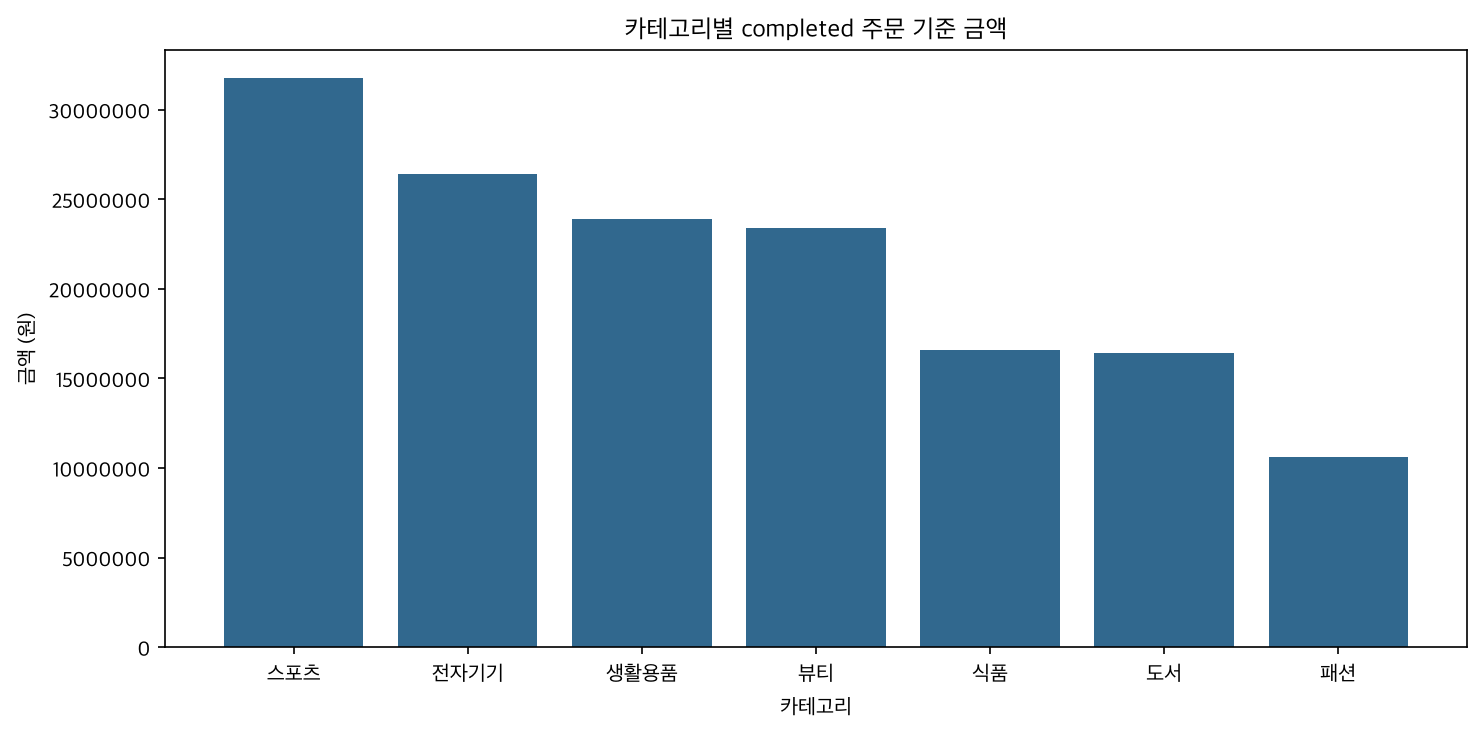

In [14]:
display(Image(filename=str(FIGURE_DIR / "ch08_category_sales.png")))

선택 이유: 범주 간 금액 크기·순위를 0 기준 막대로 비교한다. 실제 `Rectangle.get_height()`와 카테고리 집계 7개 값의 최대 차이는 **0원**이다.

직접 관찰: 스포츠 막대가 가장 높고 패션이 가장 낮다. 해석: 완료 주문 금액 기여의 차이다. 그래프만으로 단가·수량 중 무엇이 차이를 만들었는지, 수익성이 높은지는 말할 수 없다.

## 답안 6. 그래프 2 — 월 금액과 주문 수

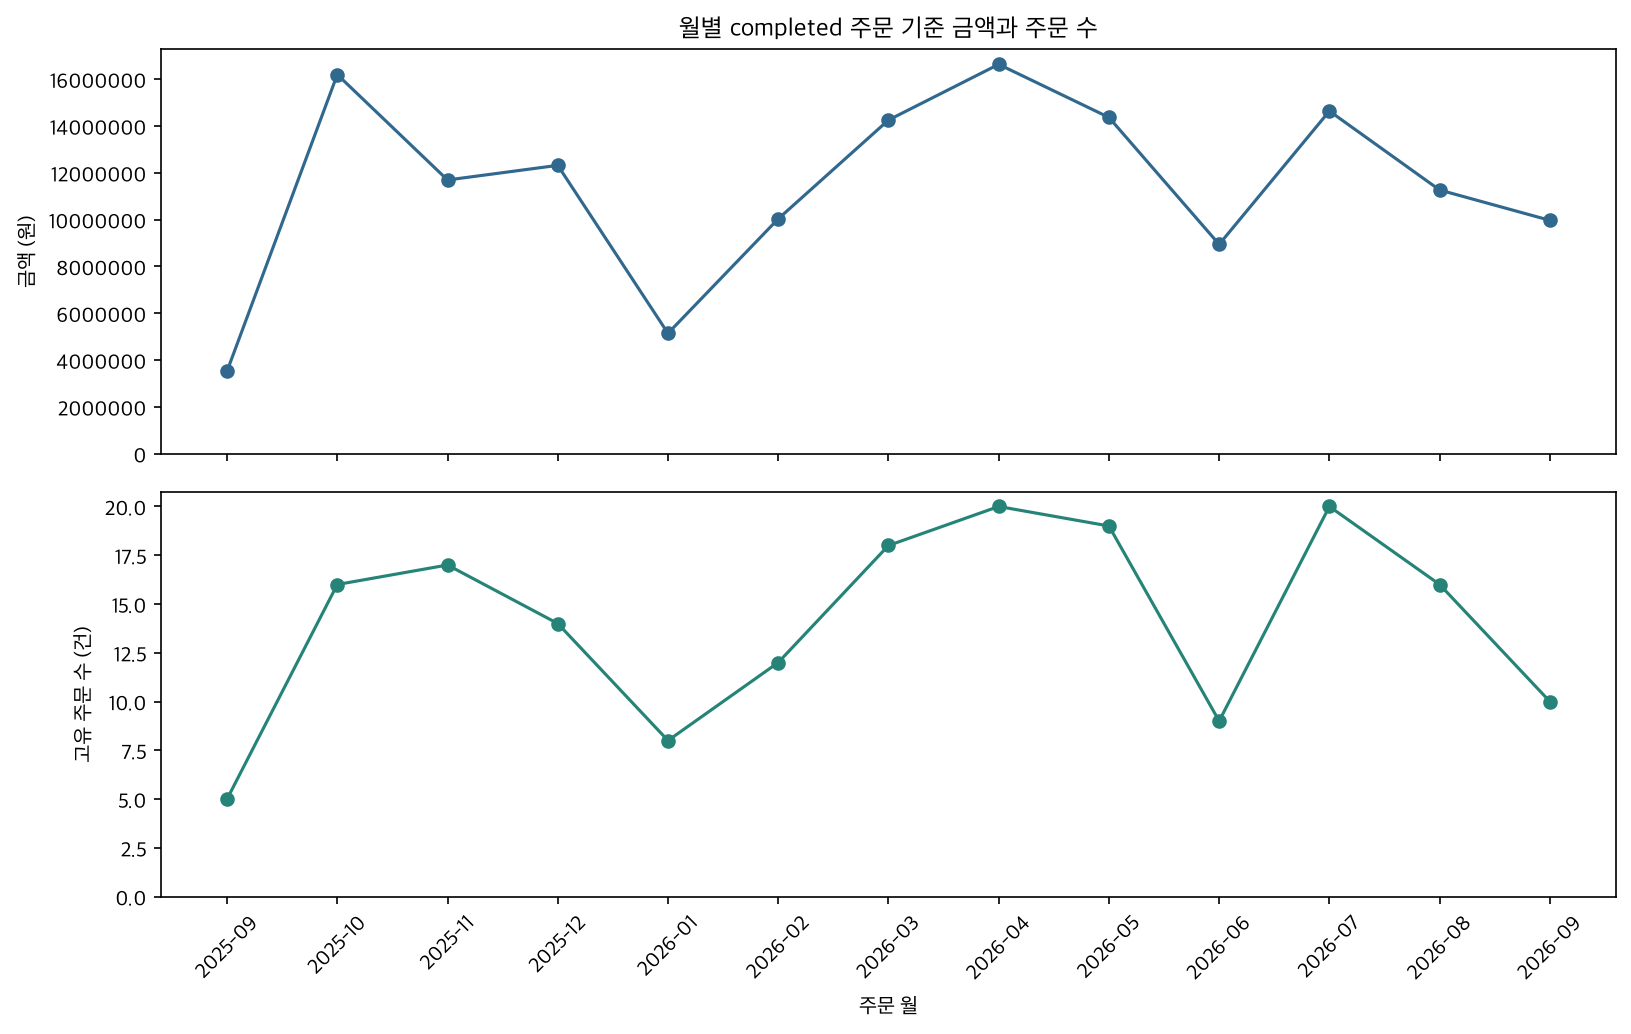

In [15]:
display(Image(filename=str(FIGURE_DIR / "ch08_monthly_sales.png")))

선택 이유: 시간 순서의 변화를 선으로 나타내며 금액·주문 수를 각 패널로 나누어 단위를 명시한다. 두 `Line2D.get_ydata()`와 각 월 집계 13개 값의 최대 차이는 **0원·0건**이다.

직접 관찰: 2026-04 금액이 가장 높으며 2026-04·07은 모두 20주문이다. 해석: 같은 주문 수에서도 주문당 금액 차이가 있다. 그래프만으로 프로모션 효과나 계절성을 말할 수 없다. 첫·마지막 9월은 부분 관측 월이라는 제한을 함께 읽는다.

## 답안 6. 그래프 3 — 상위 익명 고객 금액

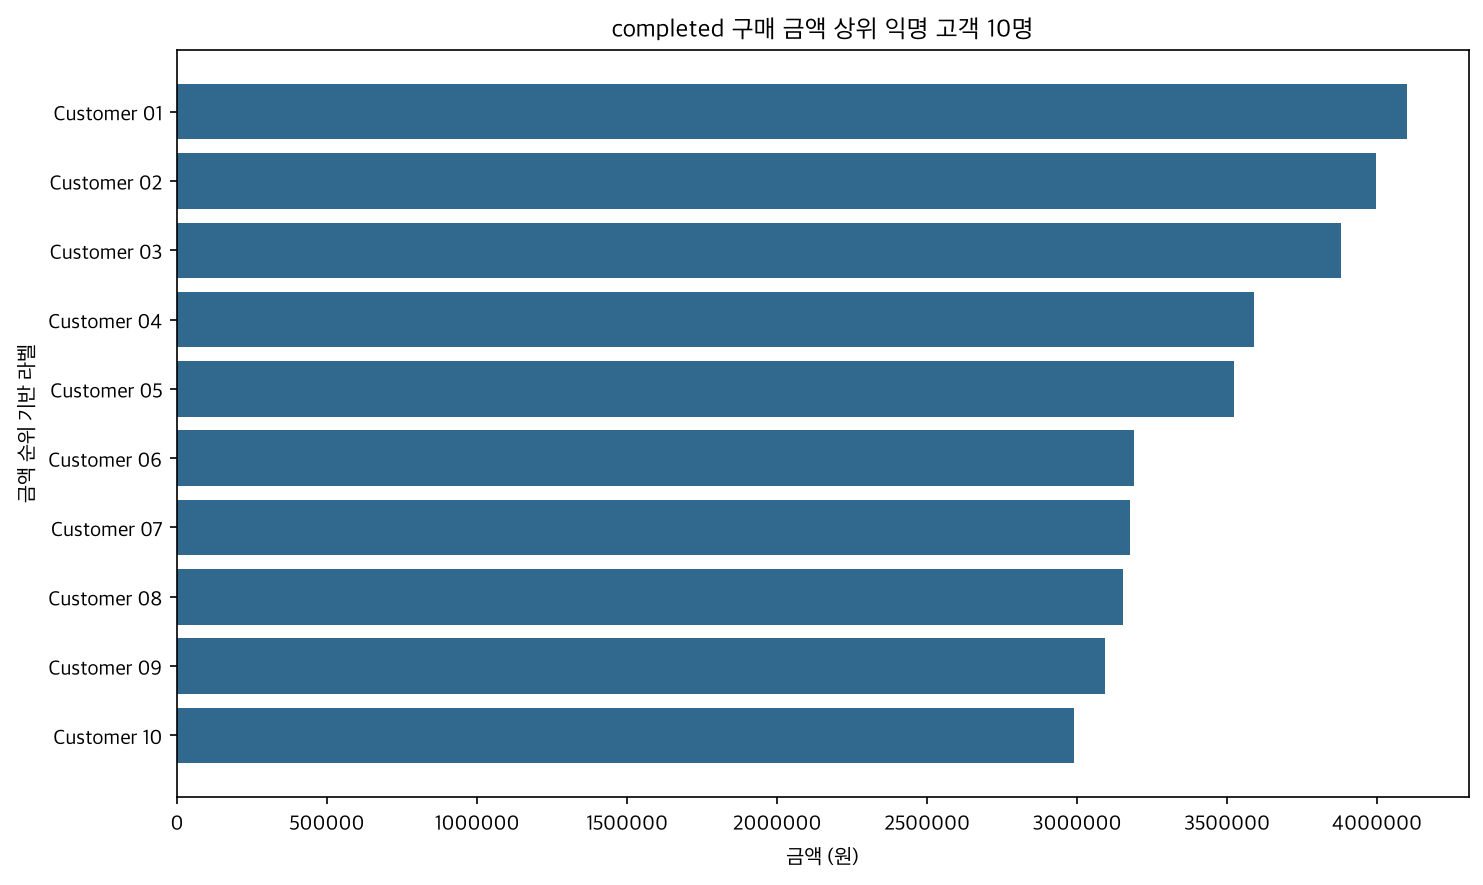

In [16]:
display(Image(filename=str(FIGURE_DIR / "ch08_top_customers.png")))

선택 이유: 상위 10명 순위와 익명 라벨을 가로 막대로 비교한다. 실제 `Rectangle.get_width()`와 상위 10명 집계의 최대 차이는 **0원**이다. 상위 10명만 표시했으므로 이 그래프의 합계가 전체 완료 금액과 같을 필요는 없다. 전체 고객 CSV의 합계로 총합 검증을 수행했다.

직접 관찰: Customer 01의 금액 4,100,000원이 표시한 고객 중 가장 높다. 해석: 현재 범위의 구매 금액 순위이다. 그래프만으로 장기 고객 가치나 구매 동기를 말할 수 없다.

## 14. Markdown 보고서 생성

보고서에는 계산 기준, PK/FK·병합, `line_total`, total consistency, 개인정보, 최종 Validation을 함께 남깁니다.


In [17]:
report_text = build_midterm_report(
    dataset_summary,
    preprocessing_comparison,
    key_duplicate_checks,
    relationship_checks,
    analysis_tables,
    interpretation_notes,
)

report_path = REPORT_DIR / "ch08_midterm_report.md"
report_path.write_text(report_text, encoding="utf-8")

print("보고서 저장:", report_path)
print(report_text[:1800])


보고서 저장: /Users/kjj/MyLLMGit/llm-data-analysis-study/chapter08/reports/ch08_midterm_report.md
# Chapter 8 중간 프로젝트 보고서

## 1. 분석 목적

온라인 쇼핑몰 데이터를 사용해 completed 주문 기준 금액과 고객 구매 패턴을 분석했습니다.

## 2. 분석 기준

- 금액성 분석은 `order_status == "completed"`인 주문만 포함했습니다.
- `line_total = quantity × unit_price` 관계를 검증했습니다.
- 취소·환불 등 non-completed 주문을 포함한 금액은 전체 주문 상세 금액으로 구분했습니다.
- 공개 고객 결과에서는 이름·연락처·원본 고객 ID를 제외하고 순위 기반 익명 라벨을 사용했습니다.
- 병합은 관계 검증, `validate`, 행 수, 미매칭을 확인했습니다.
- 같은 completed 범위의 카테고리·월·고객 총합을 source total과 대조했습니다.

## 3. 데이터 개요

```text
    dataset  rows  columns  missing_values  duplicated_rows
  customers   150        6               0                0
   products   100        4               0                0
     orders   300        5               0                0
order_items   764        5               0                0
```

## 4. 전처리 전후 비교

```text
    dataset  rows_raw  columns_raw  rows_processed  columns_processed
  customers       150            6             150          

## 15. 전체 파이프라인 재실행

단계별 셀을 확인한 뒤에는 `run_midterm_project()`로 원본부터 보고서까지 다시 실행합니다. Notebook의 이전 메모리 상태에 의존하지 않는지 확인하는 단계입니다.


In [18]:
# 별도 Python 프로세스에서 실제 제출 명령을 실행하여 메모리 의존을 제거한다.
import subprocess
before_tables = {name: df.copy(deep=True) for name, df in {
    "ch08_category_sales.csv": category_sales,
    "ch08_monthly_sales.csv": monthly_sales,
    "ch08_customer_sales.csv": customer_sales_public,
    "ch08_total_consistency_check.csv": total_consistency,
}.items()}
proc = subprocess.run([sys.executable, "scripts/run_midterm_project.py"], cwd=PROJECT_ROOT,
                      capture_output=True, text=True, check=True)
(REPORT_DIR / "ch08_reproduce.log").write_text(proc.stdout, encoding="utf-8")
print(proc.stdout)
rerun_checks = []
for filename, before in before_tables.items():
    after = pd.read_csv(REPORT_DIR / filename)
    pd.testing.assert_frame_equal(before.reset_index(drop=True), after, check_dtype=False, check_exact=True)
    rerun_checks.append({"file": filename, "status": "PASS"})
display(pd.DataFrame(rerun_checks))
print("별도 프로세스 재실행과 Notebook 결과 정확 일치: PASS")


Python: 3.12.0
Final Validation
                                 check                value             expected status
                          pk_integrity             all PASS             all PASS   PASS
                          fk_integrity                    0                    0   PASS
                     merge_checks_pass             all PASS             all PASS   PASS
                line_total_consistency                    0                    0   PASS
           completed_total_consistency            all match            all match   PASS
          category_sales_ratio_pct_sum                100.0                100.0   PASS
completed_rows_with_invalid_order_date                    0                    0   PASS
          public_customer_columns_safe no forbidden columns no forbidden columns   PASS
Additional Validation
                             check                                                                       value                                            

,file,status
0,ch08_category_sales.csv,PASS
1,ch08_monthly_sales.csv,PASS
2,ch08_customer_sales.csv,PASS
3,ch08_total_consistency_check.csv,PASS


별도 프로세스 재실행과 Notebook 결과 정확 일치: PASS


## 답안 10. 프로젝트 재현 확인

실제 실행 명령은 저장소 루트의 `python scripts/run_midterm_project.py`이다. 위 코드는 Notebook 커널과 같은 Python 실행 파일로 **별도 프로세스**를 띄워 이 명령을 실행하고 종료 코드 0을 확인했다. 생성된 카테고리·월·전체 익명 고객·총합 CSV 네 파일을 Notebook 계산과 정확 비교했다. 실행 로그는 `reports/ch08_reproduce.log`에 저장했다.

재현 가능한 흐름은 중간 셀의 이전 변수에 의존하는 결과와 실제 입력에 근거한 결과를 구분하게 한다. 네트워크·LLM 응답·API 키 없이 원본부터 다시 계산하므로 입력과 코드가 같을 때 결과를 확인할 수 있다. 출력은 `chapter08/reports/`, `chapter08/images/`에 모아 이전 장의 결과를 보존한다.

## 16. 최종 산출물 검증

필수 CSV·PNG·Markdown이 존재하고 비어 있지 않은지 확인합니다.


In [19]:
expected_outputs = [
    REPORT_DIR / "ch08_midterm_report.md",
    REPORT_DIR / "ch08_dataset_summary.csv",
    REPORT_DIR / "ch08_preprocessing_comparison.csv",
    REPORT_DIR / "ch08_key_duplicate_checks.csv",
    REPORT_DIR / "ch08_relationship_checks.csv",
    REPORT_DIR / "ch08_merge_checks.csv",
    REPORT_DIR / "ch08_line_total_check.csv",
    REPORT_DIR / "ch08_date_checks.csv",
    REPORT_DIR / "ch08_amount_scope_summary.csv",
    REPORT_DIR / "ch08_total_consistency_check.csv",
    REPORT_DIR / "ch08_project_validation.csv",
    REPORT_DIR / "ch08_category_sales.csv",
    REPORT_DIR / "ch08_monthly_sales.csv",
    REPORT_DIR / "ch08_customer_sales.csv",
    REPORT_DIR / "ch08_order_status_summary.csv",
    REPORT_DIR / "ch08_interpretation_notes.csv",
    FIGURE_DIR / "ch08_category_sales.png",
    FIGURE_DIR / "ch08_monthly_sales.png",
    FIGURE_DIR / "ch08_top_customers.png",
]

all_outputs_valid = True
for path in expected_outputs:
    valid = path.exists() and path.stat().st_size > 0
    all_outputs_valid &= valid
    print(path.name, "OK" if valid else "MISSING OR EMPTY")

assert all_outputs_valid
print("전체 산출물 검증: PASS")


ch08_midterm_report.md OK
ch08_dataset_summary.csv OK
ch08_preprocessing_comparison.csv OK
ch08_key_duplicate_checks.csv OK
ch08_relationship_checks.csv OK
ch08_merge_checks.csv OK
ch08_line_total_check.csv OK
ch08_date_checks.csv OK
ch08_amount_scope_summary.csv OK
ch08_total_consistency_check.csv OK
ch08_project_validation.csv OK
ch08_category_sales.csv OK
ch08_monthly_sales.csv OK
ch08_customer_sales.csv OK
ch08_order_status_summary.csv OK
ch08_interpretation_notes.csv OK
ch08_category_sales.png OK
ch08_monthly_sales.png OK
ch08_top_customers.png OK
전체 산출물 검증: PASS


## 17. LLM 검토 프롬프트 예시

원본 고객 행이나 직접 식별정보 대신 비식별 검증 Evidence를 제공합니다.

```text
온라인 쇼핑몰 중간 프로젝트 결과를 검토해 주세요.

계산 기준:
- line_total = quantity × unit_price
- 금액성 분석은 order_status == completed만 사용

검증 결과:
- PK 결측/중복: 0
- FK 미매칭: 0
- merge checks: PASS
- category/month/customer totals: source total과 일치
- completed 주문 날짜 오류: 0
- 공개 고객 CSV에 원본 customer_id 없음

다음을 검토해 주세요.
1. 아직 확인하지 않은 분석 위험
2. 과도한 해석이 될 수 있는 표현
3. 보고서에 반드시 적어야 할 계산 기준
4. 추가로 필요한 검증
5. 데이터에 없는 원인은 추정하지 않기
```

LLM은 검토 범위를 넓히는 도구이지 프로젝트의 최종 승인자가 아닙니다.


## 답안 9. 실제 LLM 활용 기록

| 항목 | 기록 |
|---|---|
| 사용 여부·도구 | 사용 — OpenAI Codex |
| 사용 목적 | 공식 흐름 구현 보조, 검증 항목 설계, 그래프·해석·답안 초안 작성 |
| Safe Context | 과제 문구·공식 공개 코드, 실제 컬럼명과 품질 건수, 비식별 집계와 PASS/FAIL |
| Prompt 요약 | 과제 요구에 맞춰 chapter08 제출물을 작성하고 총합·PK/FK·개인정보·재현성을 점검해 달라는 요청 |
| 제안·실제 반영 | 공식 Notebook 복사, completed 범위 통일, 검증표 저장, 익명 순위, 별도 프로세스 재실행·결과 비교 반영 |
| 수정·보류 | 기존 장의 processed 입력 대신 이번 공식 raw 사용. 공개 processed 고객 파일 저장 제거. 수익성·광고 효과·선호 원인에 대한 단정은 채택하지 않음 |
| 검증 근거 | 실제 CSV로 다시 계산한 148,990,000원, 네 합계, 원본 ID집합 독립 계산, 그래프 객체 값, 저장 CSV·입력 해시·실행 로그 |
| 사람의 재검증 상태 | 이 제출물 생성 과정의 재검증은 자동 코드로 수행했다. 작성자가 직접 재검토했다고 허위 기록하지 않는다. 제출자는 위 표·원본 산식·그래프·최종 PASS 및 아래 요약의 표현을 직접 확인할 수 있다. |

LLM이 제시한 숫자를 그대로 입력하지 않고 Python이 실제 입력에서 산출한 수치만 답안에 사용했다. 자동 검증과 작성자의 직접 검토는 구분한다.

## 18. 실습 과제

1. 핵심 EDA 결과 3개를 선택하고 각각 근거와 한계를 작성합니다.
2. 대표 그래프 2~4개를 선택하고 원본 집계값과 일치하는지 확인합니다.
3. `ch08_total_consistency_check.csv`와 `ch08_project_validation.csv`를 확인합니다.
4. 공개 고객 CSV에 개인정보가 없는지 다시 확인합니다.
5. LLM을 사용했다면 목적·Prompt 요약·제안·반영 여부·사람의 검증 근거를 기록합니다.
6. `python scripts/run_midterm_project.py`로 전체 프로젝트를 다시 실행하고 Notebook의 핵심 수치와 비교합니다.


In [20]:
additional_validation = extra_evidence(raw_data, processed_data, analysis_tables, REPORT_DIR)
display(additional_validation)
manifest_after = input_manifest(PROJECT_ROOT)
assert manifest_before.equals(manifest_after), "입력 파일 변경 발견"
manifest_after.to_csv(REPORT_DIR / "ch08_input_manifest.csv", index=False)
print("원본·기존 processed SHA-256 보존: PASS")
print("공식 Validation", len(project_validation), "/ 추가 Validation", len(additional_validation), "/ 그래프 검증", len(chart_validation), "항목 모두 PASS")


,check,value,expected,status
0,raw_pk_integrity,True,True,PASS
1,raw_fk_integrity,0,0,PASS
2,independent_raw_completed_amount,148990000,148990000,PASS
3,completed_scope,True,True,PASS
4,completed_order_coverage,184,184,PASS
5,all_order_coverage,300,300,PASS
6,all_order_dates_valid,0,0,PASS
7,future_order_dates_asof_2026_11_04,0,0,PASS
8,category_not_missing,0,0,PASS
9,positive_finite_amount_inputs,True,True,PASS


원본·기존 processed SHA-256 보존: PASS
공식 Validation 8 / 추가 Validation 23 / 그래프 검증 4 항목 모두 PASS


## 제출 전 확인표

- [x] 실행 코드보다 먼저 질문 3개·범위·지표·완료 기준 작성
- [x] 원본 4종에서 시작, 전후 shape·컬럼·결측·중복·행 변화 설명
- [x] 원본·전처리 PK/FK와 병합 validate·행 수·미매칭 확인
- [x] line_total, 전체/완료 금액, 상세 수/주문 수 구분
- [x] EDA 3개에 관찰·판단·업무 의미·한계 작성
- [x] 같은 completed 범위의 총합·날짜 검증
- [x] 그래프 3개와 집계표의 실제 값 비교
- [x] 저장된 익명 고객 CSV 재검사, 원본 고객 행 미출력
- [x] 공식 Validation·추가 검증·그래프 검증 PASS
- [x] 별도 프로세스 전체 재실행, Notebook과 결과 정확 비교
- [x] LLM 사용·자동 검증 근거·사람 직접 검토 상태를 구분해 기록

GitHub 업로드 후에는 최종 Notebook URL에서 렌더링·실행 출력·표·그림을 확인하고 **파일 URL**을 LMS에 제출한다. 이 Notebook의 로컬 실행은 GitHub 업로드나 LMS 제출을 수행하지 않는다.

## 정리

이번 장에서는 원본 데이터 확인, 전처리, PK/FK, 병합, `line_total`, completed 범위, total consistency, 날짜, 개인정보, 시각화, 보고서, 최종 Validation을 하나의 프로젝트로 연결했습니다.

기억할 핵심은 다음과 같습니다.

```text
실행 성공 ≠ 검증 완료
같은 의미의 숫자는 서로 다른 집계에서도 같아야 한다
공개 결과에는 불필요한 개인정보를 남기지 않는다
프로젝트는 원본부터 다시 실행할 수 있어야 한다
```


## 답안 11. 최종 프로젝트 요약

1. **관찰:** 스포츠가 완료 금액 **31,743,000원·21.31%**로 가장 크다. **해석:** 관측된 금액 기여가 상대적으로 높다. **근거:** 7개 카테고리 집계와 총합 148,990,000원. **확인 가치:** 수량·평균 판매 단가별 기여를 분해할 후보이다. **한계:** 원가·방문 정보가 없어 이익이나 선호 원인은 판단하지 못한다.
2. **관찰:** 2026-04와 2026-07은 각각 **20주문**이지만 금액은 **16,634,000원·14,639,000원**이다. **해석:** 주문 수 이외에 주문당 금액 차이가 있다. **근거:** 월별 금액·고유 주문 수·주문당 금액과 선그래프. **확인 가치:** 상품 구성·수량·단가를 나누어 변동을 설명할 필요가 있다. **한계:** 광고·프로모션·재고 정보가 없고 양 끝 9월은 부분 관측 월이다.
3. **관찰:** Customer 01은 **5주문·4,100,000원**, 상위 10명 합계는 **34,694,000원·23.29%**이다. **해석:** 현재 구매 규모와 횟수를 함께 봐야 고객별 차이를 설명할 수 있다. **근거:** 전체 익명 고객 집계와 상위 10명 그래프. **확인 가치:** 최근 구매일·구매 빈도와 관측 기간을 보완한 고객군 분석의 출발점이다. **한계:** 장기 충성도·생애 가치·구매 동기를 입증하지 않는다.

가장 중요한 업무·분석적 의미는 서로 다른 집계에서도 같은 완료 주문 금액이 보존된다는 근거 위에서 우선 확인할 범주·월·고객군을 정했다는 것이다. 실습 데이터의 결과를 실제 시장 전체로 일반화하지 않는다.

다음 분석은 ① 카테고리 금액을 수량·판매 단가로 분해, ② 완전 관측 월끼리 주문 수·주문당 금액·상품 구성을 비교, ③ 고객별 관측 기간을 보정하고 최근 구매일·반복 구매를 분석하는 순서로 제안한다. 사업 적용 전에는 원천 시스템·할인·환불 정의·원가와 수집 범위를 확인해야 한다.